In [1]:
import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import math
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def lorenz96_rhs(x, F = 8.0):
    """
    Lorenz-96 vector field.

    x: Tensor of shape (..., N)
    F: scalar or tensor broadcastable to x[..., 0]

    Returns: dx/dt with same shape as x
    """
    # Periodic neighbors using roll
    x_ip1 = torch.roll(x, shifts=-1, dims=-1)  # x_{i+1}
    x_im1 = torch.roll(x, shifts=+1, dims=-1)  # x_{i-1}
    x_im2 = torch.roll(x, shifts=+2, dims=-1)  # x_{i-2}

    # dx_i/dt = (x_{i+1} - x_{i-2}) * x_{i-1} - x_i + F
    return (x_ip1 - x_im2) * x_im1 - x + torch.as_tensor(F, device=x.device, dtype=x.dtype)


def rk4_step(
    x,
    dt,
    rhs=lorenz96_rhs,
    rhs_args = (),
    rhs_kwargs = None,
):
    """
    One Runge-Kutta 4 step: x_{n+1} = x_n + dt/6*(k1 + 2k2 + 2k3 + k4).
    """
    if rhs_kwargs is None:
        rhs_kwargs = {}

    k1 = rhs(x, *rhs_args, **rhs_kwargs)
    k2 = rhs(x + 0.5 * dt * k1, *rhs_args, **rhs_kwargs)
    k3 = rhs(x + 0.5 * dt * k2, *rhs_args, **rhs_kwargs)
    k4 = rhs(x + dt * k3, *rhs_args, **rhs_kwargs)

    return x + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


@torch.no_grad()
def integrate_lorenz96(
    x0,
    dt,
    steps,
    F = 8.0,
    save_every= 1,
):
    """
    Integrate Lorenz-96 forward with RK4.

    x0: (..., N) initial condition
    dt: timestep
    steps: number of RK4 steps
    F: forcing
    save_every: store every k-th step (including step 0)

    Returns:
      traj: (T, ..., N) where T = steps//save_every + 1
    """
    x = x0.clone()
    out = [x0.clone()]
    

    rhs_kwargs = {"F": F}
    for s in range(1, steps + 1):
        x = rk4_step(x, dt, rhs=lorenz96_rhs, rhs_kwargs=rhs_kwargs)
        if (s % save_every) == 0:
            out.append(x.clone())

    return torch.stack(out, dim=0)


# Example usage:
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float32

    B, N = 100, 40
    x0 = torch.randn(B, N, device=device, dtype=dtype)
    T = 500
    traj = integrate_lorenz96(x0, dt=0.01, steps=T, F=8.0, save_every=1)
    print(traj.shape)  # (101, 16, 40)

torch.Size([501, 100, 40])


In [101]:

T, B, N = traj.shape
p = 1
horizon = 10
L = 50
gamma = 0.95

Hmax = horizon  # or 50
t0 = L - 1
t1 = T - 1 - Hmax
t_vals = list(range(t0, t1+1))
n_t = len(t_vals)

traj_obs = traj[:, :, :p]                    # (T,B,p)

# standardize observations (inputs only), using TRAIN trajectories ideally
mu = traj_obs.mean(dim=(0,1), keepdim=True)   # (1,1,p)
sd = traj_obs.std(dim=(0,1), keepdim=True) + 1e-6
obs_std = (traj_obs - mu) / sd                # (T,B,p)


# lag weights, most recent first: [w0 for o_t, w1 for o_{t-1}, ...]
w = (gamma ** torch.arange(L, device=traj.device, dtype=traj.dtype))  # (L,)

Y = torch.empty(B, n_t, p,   device=traj.device, dtype=traj.dtype)

U = torch.empty(B, n_t, p*L, device=traj.device, dtype=traj.dtype)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = obs_std[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        window = window * w[:, None]
        U[j, i, :] = window.reshape(-1)

# flatten across trajectories/time
U_flat = U.reshape(B*n_t, p*L)
Y_flat = Y.reshape(B*n_t, p)
sample_size = 30000
idx = torch.randperm(U_flat.shape[0], device=U_flat.device)[:sample_size]
U_train = U_flat[idx]
Y_train_raw = Y_flat[idx]

Y_mean = Y_flat.mean(dim=0, keepdim=True)
Y_std  = Y_flat.std(dim=0, keepdim=True) + 1e-6

Y_train = (Y_train_raw - Y_mean) / Y_std

In [102]:
def phi(u, Omega, b, sigma=1.0, P=512):
    # u: (d_u,)
    z = math.sqrt(2.0 / P) * torch.cos(Omega @ u + b)  # (P,)
    return torch.cat([u, sigma * z], dim=0)            # (d_u+P,)

def solve_W(U, Y, Omega, b, sigma=1.0, P=512, lam=1.0):
    # U: (n, d_u), Y: (n, p_out)
    n, d_u = U.shape
    p_out = Y.shape[1]
    d = d_u + P

    G = torch.zeros(d, d, device=U.device, dtype=U.dtype)
    H = torch.zeros(d, p_out, device=U.device, dtype=U.dtype)

    for i in range(n):
        phi_i = phi(U[i], Omega, b, sigma, P)              # (d,)
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, Y[i])                      # (d,p_out)
    G /= n
    H /= n

    W = torch.linalg.solve(G + lam * torch.eye(d, device=U.device, dtype=U.dtype), H)  # (d,p_out)
    return W

def horizon_forecast(test_traj, Omega, b, sigma, p, P, W,
                     U_mean, U_std, Y_mean, Y_std, L, horizon=10):
    T = test_traj.shape[0]
    n_t = T - horizon - L + 1

    test_std = (test_traj - U_mean) / U_std
    preds = torch.empty(n_t, p, device=test_traj.device, dtype=test_traj.dtype)

    for t in range(n_t):
        window = test_std[t:t+L, :]                    # (L,p), oldest->newest
        window = torch.flip(window, dims=[0])          # newest->oldest
        u_t = window.reshape(-1)                       # (pL,)
        do_std = phi(u_t, Omega, b, sigma, P) @ W      # (p,)
        do = Y_mean + Y_std * do_std                   # (p,)
        o_t = test_traj[t+L-1, :]                      # current obs in original space
        preds[t, :] = o_t + do                         # forecast o_{t+h}
    return preds

def model_mse(y_true, y_pred):
    return ((y_true - y_pred)**2).mean()


In [103]:
M = U_train.shape[0]
idx1 = torch.randint(0, M, (sample_size,), device=U_train.device)
idx2 = torch.randint(0, M, (sample_size,), device=U_train.device)
d = torch.linalg.norm(U_train[idx1] - U_train[idx2], dim=1)
ell = d.median()
sigma = 1
P = 512
mvn = MultivariateNormal(torch.zeros(U_train.shape[1]),ell**-2*torch.eye(U_train.shape[1]))
Omega = torch.randn(P, U_train.shape[1], device=device, dtype=dtype) / ell
b = (2*torch.pi*torch.rand((P,), device=device, dtype=dtype))

W = solve_W(U_train, Y_train, Omega, b, sigma=1.0, P=P, lam=10**1)


In [104]:
B_test = 1
x0 = torch.randn(B_test, N, device=device, dtype=dtype)
traj_test = integrate_lorenz96(x0, dt=0.01, steps=500, F=8.0, save_every=1)
traj_test_obs = traj_test[:, :, :p]

In [105]:
traj_pred = horizon_forecast(
    traj_test_obs[:,0,:],   # (T,p)
    Omega, b, sigma, p, P, W,
    mu.squeeze(0).squeeze(0), sd.squeeze(0).squeeze(0),
    Y_mean, Y_std, L,
    horizon=horizon
)

In [106]:
# T = traj_test_obs.shape[0]
# n_t = T - horizon - L + 1

y_pred = traj_pred                                    # (n_t,p)
y_true = traj_test_obs[L-1+horizon : L-1+horizon+n_t, 0, :]  # (n_t,p)

mse = ((y_true - y_pred)**2).mean()

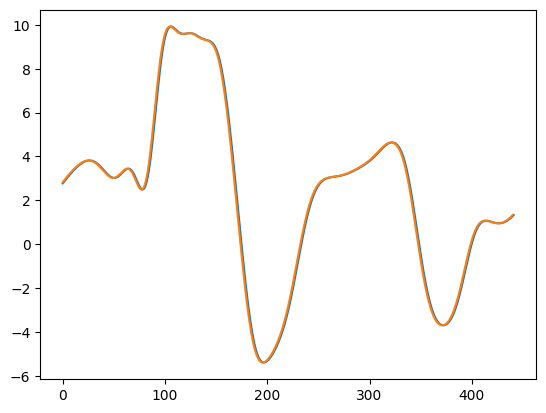

In [107]:
plt.plot(traj_pred[:,p-1])
plt.plot(traj_test_obs[L:-horizon,0,p-1])

In [108]:
pers_mse = ((traj_test_obs[horizon:,0,:] - traj_test_obs[:-horizon,0,:])**2).mean()
pers_mse

tensor(2.4658)

In [109]:
y_pred = traj_pred                       # (n_t, p)
y_true = traj_test_obs[L-1+horizon : L-1+horizon+n_t, 0, :]   # (n_t, p)

mse = ((y_true - y_pred)**2).mean()

In [110]:
mse

tensor(2.6825)

In [114]:
k = 50
U_all = U.reshape(B*n_t, p*L).detach().cpu().numpy()
pca = PCA(n_components=k)
       # (B*n_t, k)
S_all = pca.fit_transform(U_all)                      # (B*n_t,k)
S_seq = torch.tensor(S_all, device=U.device, dtype=U.dtype).reshape(B, n_t, k)

mu_u = torch.tensor(pca.mean_, device=U.device, dtype=U.dtype)           # (d_u,)
V_k  = torch.tensor(pca.components_, device=U.device, dtype=U.dtype)     # (k, d_u)

# 2) reshape latent sequence
S_seq = torch.tensor(S_all, device=U.device, dtype=U.dtype).reshape(B, n_t, k)

# 3) build pairs
S_flat      = S_seq[:, :-1, :].reshape(B*(n_t-1), k)
S_next_flat = S_seq[:, 1:,  :].reshape(B*(n_t-1), k)

# 4) ridge solve for A
beta = 1e-5
G = S_flat.T @ S_flat
H = S_flat.T @ S_next_flat
A_T = torch.linalg.solve(G + beta*torch.eye(k, device=U.device, dtype=U.dtype), H)
A = A_T.T

In [115]:
B_test = 1 
x0 = torch.randn(B_test, N, device=device, dtype=dtype) 
traj_test = integrate_lorenz96(x0, dt=0.01, steps=500, F=8.0, save_every=1) 
traj_test_obs = traj_test[:, :, :p]

o = traj_test_obs[:, 0, :]             # (T, p)
o_std = (o - mu.squeeze(0).squeeze(0)) / sd.squeeze(0).squeeze(0)   # (T,p)


In [116]:
T = o.shape[0]

t0 = L - 1
t1 = T - 1 - horizon          # IMPORTANT
t_vals = list(range(t0, t1 + 1))
n_t = len(t_vals)

U_test = torch.empty(n_t, p*L, device=o.device, dtype=o.dtype)
for i, t in enumerate(t_vals):
    window = o_std[t-L+1:t+1, :]
    window = torch.flip(window, dims=[0])
    window = window * w[:, None]
    U_test[i, :] = window.reshape(-1)

S_test = (U_test - mu_u) @ V_k.T

A10 = torch.matrix_power(A, horizon)
S10_pred = S_test @ A10.T
U10_pred = mu_u + (S10_pred @ V_k)
o10_pred_std = U10_pred[:, :p]
mu_obs = mu.squeeze(0).squeeze(0)   # (p,)
sd_obs = sd.squeeze(0).squeeze(0)   # (p,)
o10_pred = mu_obs + sd_obs * o10_pred_std


t_tensor = torch.tensor(t_vals, device=o.device)
o_true_h = o[t_tensor + horizon, :]      # now always in-bounds
o_pers   = o[t_tensor, :]
mse      = ((o10_pred - o_true_h)**2).mean()
pers_mse = ((o_pers   - o_true_h)**2).mean()

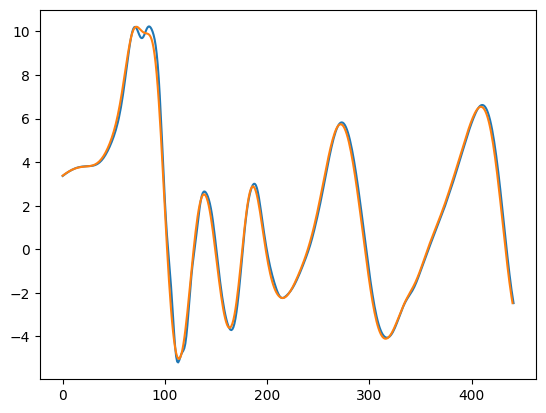

In [117]:
plt.plot(o10_pred[:,p-1])
plt.plot(traj_test_obs[L+horizon:,0,p-1])

In [118]:
S = S_seq[:, :-1, :].reshape(-1, k)

traj_obs = traj[:, :, :p]                    # (T,B,p)

S0   = S_seq[:, :-horizon, :].reshape(-1, k)
dS_h = (S_seq[:, horizon:, :] - S_seq[:, :-horizon, :]).reshape(-1, k)


# standardize observations (inputs only), using TRAIN trajectories ideally
mu = traj_obs.mean(dim=(0,1), keepdim=True)   # (1,1,p)
sd = traj_obs.std(dim=(0,1), keepdim=True) + 1e-6
obs_std = (traj_obs - mu) / sd                # (T,B,p)


S_train = S0.reshape(-1, k)           # (B*(n_t-h), k)


O_seq = obs_std[t_vals, :, :]          # (n_t, B, p)
O_seq = O_seq.permute(1, 0, 2)         # (B, n_t, p)  to match S_seq shape
O = O_seq[:, :-1, :].reshape(-1, p)    # (B*(n_t-1), p)


In [119]:
M = S.shape[0]
idx1 = torch.randint(0, M, (sample_size,), device=S.device)
idx2 = torch.randint(0, M, (sample_size,), device=S.device)
d = torch.linalg.norm(S[idx1] - S[idx2], dim=1)
ell = d.median()
sigma = 1
P = 512
mvn = MultivariateNormal(torch.zeros(S.shape[1]),ell**-2*torch.eye(S.shape[1]))
Omega = torch.randn(P, S.shape[1], device=S.device, dtype=dtype) / ell
b = (2*torch.pi*torch.rand((P,), device=S.device, dtype=dtype))


In [120]:
def build_W_f(S_train, dS, Omega, b,sigma = 1.0,P=512, lam=10**3):
        # U: (n, d_u), Y: (n, p_out)
    n, d_u = S_train.shape
    p_out = dS.shape[1]
    d = d_u + P

    G = torch.zeros(d, d, device=S_train.device, dtype=S_train.dtype)
    H = torch.zeros(d, p_out, device=S_train.device, dtype=S_train.dtype)

    for i in range(n):
        phi_i = phi(S_train[i], Omega, b, sigma, P)# (d,)
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, dS[i])                      # (d,p_out)
    G /= n
    H /= n

    W = torch.linalg.solve(G + lam * torch.eye(d, device=S_train.device, dtype=S_train.dtype), H)  # (d,p_out)
    
    return W

def build_C_tilde(S_train, O, lam=10**3):
    # U: (n, d_u), Y: (n, p_out)
    n, d_u = S_train.shape
    p_out = O.shape[1]
    d = d_u+1
    

    G = torch.zeros(d, d, device=S_train.device, dtype=S_train.dtype)
    H = torch.zeros(d, p_out, device=S_train.device, dtype=S_train.dtype)

    for i in range(n):
        one = torch.ones(1, device=S_train.device, dtype=S_train.dtype)
        phi_i = torch.cat([S_train[i], one])
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, O[i])                      # (d,p_out)
    G /= n
    H /= n

    C_tilde = torch.linalg.solve(G + lam * torch.eye(d, device=S_train.device, dtype=S_train.dtype), H)  # (d,p_out)
    
    return C_tilde

In [121]:
lam_f = 10**-8
lam_g = 10**-5

W_h = build_W_f(S_train,dS_h,Omega,b,sigma=1.0,P=P,lam=lam_f)


In [122]:
O_seq = obs_std[t_vals, :, :].permute(1,0,2)   # (B,n_t,p)
O0 = O_seq[:, :-horizon, :].reshape(-1, p)           # aligns with S0

C_tilde = build_C_tilde(S0, O0, lam=lam_g)
C = C_tilde[:-1, :]
d = C_tilde[-1, :]

In [123]:
o = traj_test_obs[:,0,:]         # (T_test,p)
T_test = o.shape[0]
t0 = L - 1
t1 = T_test - 1 - horizon
t_vals_test = list(range(t0, t1+1))
n_test = len(t_vals_test)
U_test = torch.empty(n_test, p*L, device=o.device, dtype=o.dtype)
for i, t in enumerate(t_vals_test):
    window = o_std[t-L+1:t+1, :]         # (L,p)
    window = torch.flip(window, dims=[0])
    window = window * w[:, None]
    U_test[i,:] = window.reshape(-1)

S_test = (U_test - mu_u) @ V_k.T         # (n_test,k)

In [124]:
def phi_batch(S, Omega, b, sigma=1.0, P=512):
    # S: (n,k), Omega: (P,k), b: (P,)
    Z = (Omega @ S.T).T + b           # (n,P)
    z = (2.0/P)**0.5 * torch.cos(Z)   # (n,P)
    return torch.cat([S, sigma*z], dim=1)  # (n,k+P

Phi0 = phi_batch(S_test, Omega, b, sigma, P)
dS_pred = Phi0 @ W_h
S_pred = S_test + dS_pred


o_pred_std = S_pred @ C + d              # (n_test,p)
o_pred = mu_obs + sd_obs * o_pred_std

t_tensor = torch.tensor(t_vals_test, device=o.device)
o_true = o[t_tensor + horizon, :]

o_pers = o[t_tensor, :]

mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

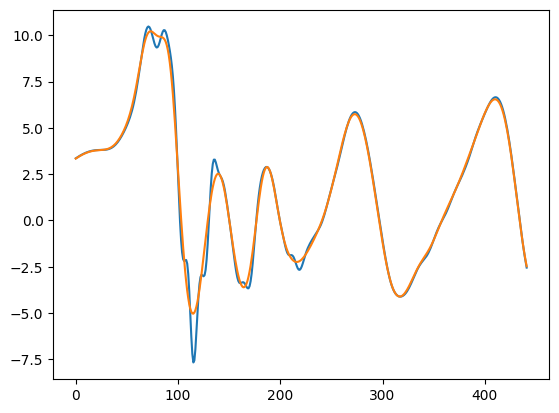

In [125]:
plt.plot(o_pred[:,p-1])
plt.plot(o_true[:,p-1])

In [89]:
print(pers_mse)
print(mse)

tensor(3.3698)
tensor(4.2847)


In [90]:

def standardize_fit(X, eps=1e-6):
    """
    X: (n, d)
    returns: Xs, mean (1,d), std (1,d)
    """
    mean = X.mean(dim=0, keepdim=True)
    std  = X.std(dim=0, keepdim=True) + eps
    Xs = (X - mean) / std
    return Xs, mean, std

def standardize_apply(X, mean, std):
    return (X - mean) / std

def unstandardize_apply(Xs, mean, std):
    return Xs * std + mean

def phi_batch(S, Omega, b, sigma=1.0):
    """
    S: (n,k)
    Omega: (P,k)
    b: (P,)
    Returns: (n, k+P) = [S, sigma*z]
    """
    n, k = S.shape
    P = Omega.shape[0]
    Z = (S @ Omega.T) + b   # (n,P)
    z = math.sqrt(2.0 / P) * torch.cos(Z)
    return torch.cat([S, sigma*z], dim=1)

def build_W_rff_ridge(S_in, Y_out, Omega, b, sigma=1.0, lam=1e-4):
    """
    S_in: (n,k) inputs
    Y_out: (n,k_out) targets
    W: (k+P, k_out)
    """
    Phi = phi_batch(S_in, Omega, b, sigma=sigma)  # (n, k+P)
    n = Phi.shape[0]
    G = (Phi.T @ Phi) / n
    H = (Phi.T @ Y_out) / n
    d = G.shape[0]
    W = torch.linalg.solve(G + lam*torch.eye(d, device=G.device, dtype=G.dtype), H)
    return W



def predict_direct_horizon_latent(S0, W_h, Omega, b, sigma=1.0):
    """
    S0: (n,k) (already standardized if that's what you trained on)
    returns dS_pred: (n,k)
    """
    Phi0 = phi_batch(S0, Omega, b, sigma=sigma)  # (n, k+P)
    return Phi0 @ W_h

In [91]:

# Standardize inputs and targets
S0s, S_mean, S_std = standardize_fit(S0)
dS_s, dS_mean, dS_std = standardize_fit(dS_h)

# Choose ell and sample Omega,b based on STANDARDIZED inputs
# (you can keep your median heuristic here)
# Omega: (P,k)
# b: (P,)

lam_f = 10**-8

W_h = build_W_rff_ridge(S0s, dS_s, Omega, b, sigma=1.0, lam=lam_f)

# 1) standardize input latents using TRAIN stats
S_test0s = standardize_apply(S_test, S_mean, S_std)

# 2) predict standardized latent increment
dS_pred_s = predict_direct_horizon_latent(S_test0s, W_h, Omega, b, sigma=1.0)

# 3) unstandardize increment back to latent units
dS_pred = unstandardize_apply(dS_pred_s, dS_mean, dS_std)

# 4) form predicted latent at horizon
S_pred_h = S_test + dS_pred


o_pred_std = S_pred_h @ C + d              # (n_test,p)
o_pred = mu_obs + sd_obs * o_pred_std

t_tensor = torch.tensor(t_vals_test, device=o.device)
o_true = o[t_tensor + horizon, :]

o_pers = o[t_tensor, :]

mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

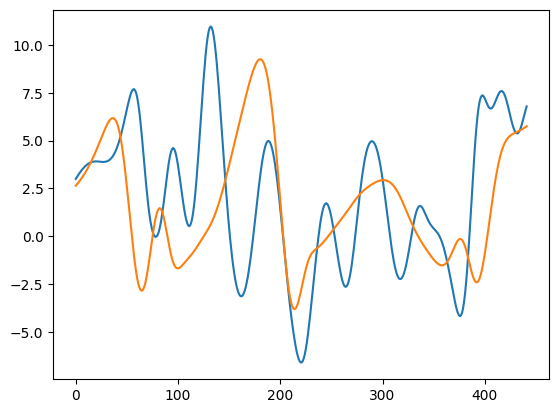

In [92]:
plt.plot(o_pred[:,p-1])
plt.plot(o_true[:,p-1])

In [76]:
mse

tensor(1.6208)

In [31]:
O_seq = obs_std[t_vals, :, :].permute(1,0,2)     # (B, n_t, p)
S_dec = S_seq.reshape(B*n_t, k)                  # (B*n_t, k)
O_dec = O_seq.reshape(B*n_t, p)                  # (B*n_t, p)

In [33]:
def median_ell(X, sample_size=5000):
    n = X.shape[0]
    idx1 = torch.randint(0, n, (sample_size,), device=X.device)
    idx2 = torch.randint(0, n, (sample_size,), device=X.device)
    d = torch.linalg.norm(X[idx1] - X[idx2], dim=1)
    return d.median()

# optional: standardize S_dec before choosing ell
S_mean = S_dec.mean(dim=0, keepdim=True)
S_std  = S_dec.std(dim=0, keepdim=True) + 1e-6
S_dec_s = (S_dec - S_mean) / S_std

ell_o = median_ell(S_dec_s)
P_o = 512
Omega_o = torch.randn(P_o, k, device=S_dec.device, dtype=S_dec.dtype) / ell_o
b_o = 2*torch.pi*torch.rand(P_o, device=S_dec.device, dtype=S_dec.dtype)

In [34]:
def psi_batch(S, Omega, b, sigma=1.0):
    # S: (n,k), Omega: (P,k), b: (P,)
    n, k = S.shape
    P = Omega.shape[0]
    Z = S @ Omega.T + b              # (n,P)
    z = math.sqrt(2.0 / P) * torch.cos(Z)
    return torch.cat([S, sigma*z], dim=1)   # (n, k+P)

def fit_rff_ridge(X_feat, Y, lam=1e-4):
    # X_feat: (n,d), Y: (n,p_out)
    n = X_feat.shape[0]
    G = (X_feat.T @ X_feat) / n
    H = (X_feat.T @ Y) / n
    d = G.shape[0]
    W = torch.linalg.solve(G + lam*torch.eye(d, device=G.device, dtype=G.dtype), H)
    return W

In [35]:
Psi = psi_batch(S_dec_s, Omega_o, b_o, sigma=1.0)  # (n, k+P_o)
W_o = fit_rff_ridge(Psi, O_dec, lam=lam_g)         # (k+P_o, p)

In [36]:
S_pred_s = (S_pred_h - S_mean) / S_std
o_pred_std = psi_batch(S_pred_s, Omega_o, b_o, sigma=1.0) @ W_o   # (n_test, p)

o_pred = mu_obs + sd_obs * o_pred_std


mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

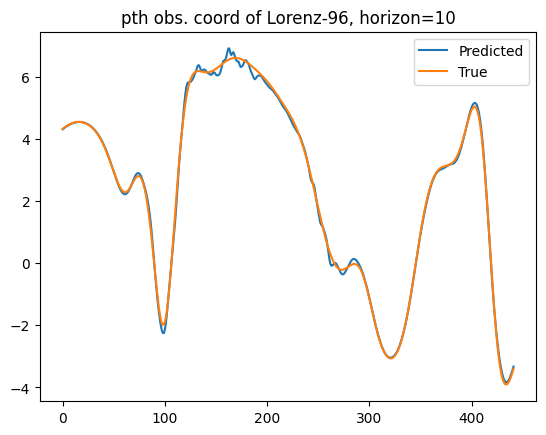

In [38]:
plt.plot(o_pred[:,p-1])
plt.plot(o_true[:,p-1])
plt.title('pth obs. coord of Lorenz-96, horizon=10')
plt.legend(['Predicted', 'True'])

In [39]:
@torch.no_grad()
def rff_features(U, Omega, b):
    # U: (n, d), Omega: (P, d), b: (P,)
    P = Omega.shape[0]
    Z = U @ Omega.T + b            # (n, P)
    return math.sqrt(2.0 / P) * torch.cos(Z)  # (n,P)

@torch.no_grad()
def encode_rff_pca(U, U_mean, U_std, Omega_e, b_e, Z_mean, V_k):
    U_stdzd = (U - U_mean) / U_std
    Z = rff_features(U_stdzd, Omega_e, b_e)                 # (n,P_e)
    Zc = Z - Z_mean[None, :]                                # (n,P_e)
    S = Zc @ V_k.T                                          # (n,k)
    return S

In [40]:
# U: (B, n_t, d_u)
U_all_std = U.reshape(B*n_t, p*L)

# U_all_std: (n,d) torch -> numpy
U_np = U_all_std.detach().cpu().numpy()

# Choose encoder RFF dim
P_e = 2000

# Choose lengthscale (median heuristic on U_all_std)
# (use your median-distance code)

M = U_train.shape[0]
idx1 = torch.randint(0, M, (sample_size,), device=U_train.device)
idx2 = torch.randint(0, M, (sample_size,), device=U_train.device)
d = torch.linalg.norm(U_train[idx1] - U_train[idx2], dim=1)
ell_e = d.median()

# Sample Omega_e, b_e
Omega_e = torch.randn(P_e, U_all_std.shape[1], device=U_all_std.device, dtype=U_all_std.dtype) / ell_e
b_e = 2*torch.pi*torch.rand(P_e, device=U_all_std.device, dtype=U_all_std.dtype)

# Compute RFF features for all train windows
Z_all = rff_features(U_all_std, Omega_e, b_e)      # (n, P_e)
Z_np = Z_all.detach().cpu().numpy()

# PCA on Z
k = 100
pca = PCA(n_components=k)
S_np = pca.fit_transform(Z_np)                     # (n,k)

# Save PCA params
Z_mean = torch.tensor(pca.mean_, device=U_all_std.device, dtype=U_all_std.dtype)      # (P_e,)
V_k = torch.tensor(pca.components_, device=U_all_std.device, dtype=U_all_std.dtype)   # (k,P_e)

# Training latents
S_all = torch.tensor(S_np, device=U_all_std.device, dtype=U_all_std.dtype)            # (n,k)
S_seq = S_all.reshape(B, n_t, k)



In [41]:
O_seq = obs_std[t_vals, :, :].permute(1,0,2)     # (B, n_t, p)
S_dec = S_seq.reshape(B*n_t, k)                  # (B*n_t, k)
O_dec = O_seq.reshape(B*n_t, p)        


# optional: standardize S_dec before choosing ell
S_mean = S_dec.mean(dim=0, keepdim=True)
S_std  = S_dec.std(dim=0, keepdim=True) + 1e-6
S_dec_s = (S_dec - S_mean) / S_std

ell_o = median_ell(S_dec_s)
P_o = 512
Omega_o = torch.randn(P_o, k, device=S_dec.device, dtype=S_dec.dtype) / ell_o
b_o = 2*torch.pi*torch.rand(P_o, device=S_dec.device, dtype=S_dec.dtype)

In [42]:
# U_test: (n_test, d_u)
U_mean = U.mean(dim=(0,1), keepdim=True)
U_std = U.std(dim=(0,1), keepdim=True)
U_test_std = (U_test - U_mean) / U_std                      # (n_test, d_u)

Z_test = rff_features(U_test_std, Omega_e, b_e)             # (n_test, P_e)
Zc_test = Z_test - Z_mean[None, :]                          # (n_test, P_e)

S_test = Zc_test @ V_k.T                                    # (n_test, k)

In [46]:
Psi = psi_batch(S_dec_s, Omega_o, b_o, sigma=1.0)  # (n, k+P_o)

lam_g = 10**-5
W_o = fit_rff_ridge(Psi, O_dec, lam=lam_g)         # (k+P_o,

S0   = S_seq[:, :-horizon, :].reshape(-1, k)
dS_h = (S_seq[:, horizon:, :] - S_seq[:, :-horizon, :]).reshape(-1, k)

S0s, S_mean, S_std = standardize_fit(S0)
dS_s, dS_mean, dS_std = standardize_fit(dS_h)

lam_f = 10**-2

W_h = build_W_rff_ridge(S0s, dS_s, Omega_o, b_o, sigma=1.0, lam=lam_f)

# 1) standardize input latents using TRAIN stats
S_test0s = standardize_apply(S_test, S_mean, S_std)

# 2) predict standardized latent increment
dS_pred_s = predict_direct_horizon_latent(S_test0s[0,:,:], W_h, Omega_o, b_o, sigma=1.0)

# 3) unstandardize increment back to latent units
dS_pred = unstandardize_apply(dS_pred_s, dS_mean, dS_std)

# 4) form predicted latent at horizon
S_pred_h = S_test + dS_pred


S_pred_s = (S_pred_h - S_mean) / S_std
o_pred_std = psi_batch(S_pred_s[0,:,:], Omega_o, b_o, sigma=1.0) @ W_o   # (n_test, p)

o_pred = mu_obs + sd_obs * o_pred_std


mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

In [47]:
S_test0s.shape

torch.Size([1, 442, 100])

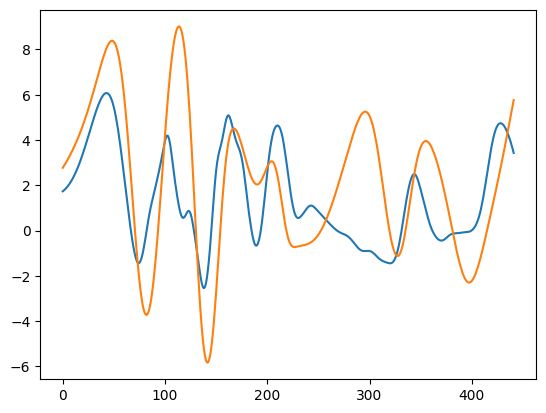

In [48]:
plt.plot(o_pred[:,1])
plt.plot(o_true[:,1])

In [49]:
mse

tensor(7.7132)

In [ ]:
pers_mse

tensor(3.3741)

In [ ]:
print(S_test.shape)
print("mean abs:", S_test.mean(dim=0).abs().mean().item())
print("std median:", S_test.std(dim=0).median().item())
print("std min/max:", S_test.std(dim=0).min().item(), S_test.std(dim=0).max().item())

torch.Size([1, 467, 100])
mean abs: 0.0479109100997448
std median: nan
std min/max: nan nan


/var/folders/7x/mpmr_n_96hv_7fkxygr63wg80000gn/T/ipykernel_3396/1590835433.py:3: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/ReduceOps.cpp:1839.)
  print("std median:", S_test.std(dim=0).median().item())
/var/folders/7x/mpmr_n_96hv_7fkxygr63wg80000gn/T/ipykernel_3396/1590835433.py:4: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/ReduceOps.cpp:1839.)
  print("std min/max:", S_test.std(dim=0).min().item(), S_test.std(dim=0).max().item())
